Use a Random Forest Classifier and compare its results with Logistic Regression by tuning hyperparameters with RandomizedSearchCV, analyzing feature importance rankings, and performing SHAP value interpretation for explainability.

In [1]:

import pandas as pd
import numpy as np

# Load the saved Task 22 dataset
df = pd.read_csv("task22_final_dataset.csv")

print("=" * 60)
print("WOMENS CLOTHING DATASET AUDIT")
print("=" * 60)

print("\n1. Dataset shape:", df.shape)

print("\n2. Column names:")
for col in df.columns:
    print("-", col)

print("\n3. Data types:")
display(df.dtypes.to_frame("Data Type"))

print("\n4. Missing values:")
display(
    df.isnull().sum()
      .to_frame("Missing Count")
      .query("`Missing Count` > 0")
)

print("\n5. Duplicate rows:", df.duplicated().sum())

print("\n6. Object / text columns:")
print(df.select_dtypes(include="object").columns.tolist())

print("\n7. Numerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\n8. Possible engineered / encoded columns:")
keywords = [
    "sentiment", "age_group", "engagement", "tfidf",
    "frequency", "encoded", "score", "duration",
    "recommend", "rating", "cluster", "component",
    "app", "website", "membership"
]

for col in df.columns:
    if any(word in col.lower() for word in keywords):
        print("-", col)

print("\n9. First five rows:")
display(df.head())


WOMENS CLOTHING DATASET AUDIT

1. Dataset shape: (23483, 28)

2. Column names:
- product_id
- category
- subcategory1
- subcategory2
- location
- channel
- customer_age
- review_title
- review_text
- rating
- recommend_flag
- vader_negative
- vader_neutral
- vader_positive
- vader_compound
- vader_sentiment_score
- vader_sentiment_label
- age_cluster_raw
- age_group
- sentiment_target
- text_clean
- text_stemmed
- text_lemmatized
- sentiment_standard
- sentiment_quantile
- sentiment_mean_based
- vader_label_normalized
- model_text

3. Data types:


,Data Type
product_id,int64
category,object
subcategory1,object
subcategory2,object
location,object
channel,object
customer_age,int64
review_title,object
review_text,object
rating,int64



4. Missing values:


,Missing Count



5. Duplicate rows: 0

6. Object / text columns:
['category', 'subcategory1', 'subcategory2', 'location', 'channel', 'review_title', 'review_text', 'vader_sentiment_label', 'age_group', 'sentiment_target', 'text_clean', 'text_stemmed', 'text_lemmatized', 'sentiment_standard', 'sentiment_quantile', 'sentiment_mean_based', 'vader_label_normalized', 'model_text']

7. Numerical columns:
['product_id', 'customer_age', 'rating', 'recommend_flag', 'vader_negative', 'vader_neutral', 'vader_positive', 'vader_compound', 'vader_sentiment_score', 'age_cluster_raw']

8. Possible engineered / encoded columns:
- rating
- recommend_flag
- vader_sentiment_score
- vader_sentiment_label
- age_cluster_raw
- age_group
- sentiment_target
- sentiment_standard
- sentiment_quantile
- sentiment_mean_based

9. First five rows:


,product_id,category,subcategory1,subcategory2,location,channel,customer_age,review_title,review_text,rating,...,age_group,sentiment_target,text_clean,text_stemmed,text_lemmatized,sentiment_standard,sentiment_quantile,sentiment_mean_based,vader_label_normalized,model_text
0,767,Initmates,Intimate,Intimates,Mumbai,Mobile,33,Not Provided,Absolutely wonderful - silky and sexy and comfortable,4,...,Age Group 2,Positive,absolutely wonderful silky and sexy and comfortable,absolut wonder silki and sexi and comfort,absolutely wonderful silky and sexy and comfortable,Positive,Negative,Neutral,Positive,Not Provided Absolutely wonderful - silky and sexy and comfortable
1,1080,General,Dresses,Dresses,Bangalore,Mobile,34,Not Provided,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite.",5,...,Age Group 2,Positive,love this dress it s sooo pretty i happened to find it in a store and i m glad i did bc i never would have ordered it online bc it s petite i bought a petite and am i love the length on me hits just a little below the knee would definitely be a true midi on someone who is truly petite,love this dress it s sooo pretti i happen to find it in a store and i m glad i did bc i never would have order it onlin bc it s petit i bought a petit and am i love the length on me hit just a littl below the knee would definit be a true midi on someon who is truli petit,love this dress it s sooo pretty i happened to find it in a store and i m glad i did bc i never would have ordered it online bc it s petite i bought a petite and am i love the length on me hit just a little below the knee would definitely be a true midi on someone who is truly petite,Positive,Positive,Positive,Positive,"Not Provided Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite."
2,1077,General,Dresses,Dresses,Gurgaon,Mobile,60,Some major design flaws,"I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was the net over layer sewn directly into the zipper - it c",3,...,Age Group 4,Neutral,i had such high hopes for this dress and really wanted it to work for me i initially ordered the petite small my usual size but i found this to be outrageously small so small in fact that i could not zip it up i reordered it in petite medium which was just ok overall the top half was comfortable and fit nicely but the bottom half had a very tight under layer and several somewhat cheap net over layers imo a major design flaw was the net over layer sewn directly into the zipper it c,i had such high hope for this dress and realli want it to work for me i initi order the petit small my usual size but i found this to be outrag small so small in fact that i could not zip it up i reorder it in petit medium which was just ok overal the top half was comfort and fit nice but the bottom half had a veri tight under layer and sever somewhat cheap net over layer imo a major design flaw was the net over layer sewn direct into the zipper it c,i had such high hope for this dress and really wanted it to work for me i initially ordered the petite small my usual size but i found this to be outrageously small so small in fact that i could not zip 

In [2]:
# Check whether the saved dataset has usable features
# and understand the sentiment-related columns.

print("DATASET VALIDATION")
print("-" * 50)

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nAge group distribution:")
display(df["age_group"].value_counts(dropna=False))

print("\nSentiment target distribution:")
display(df["sentiment_target"].value_counts(dropna=False))

print("\nVADER sentiment label distribution:")
display(df["vader_sentiment_label"].value_counts(dropna=False))

print("\nRating distribution:")
display(df["rating"].value_counts().sort_index())

print("\nNumeric columns:")
print(df.select_dtypes(include="number").columns.tolist())

DATASET VALIDATION
--------------------------------------------------
Shape: (23483, 28)
Missing values: 0
Duplicate rows: 0

Age group distribution:


age_group
Age Group 2    8681
Age Group 3    6525
Age Group 1    4538
Age Group 4    3739
Name: count, dtype: int64


Sentiment target distribution:


sentiment_target
Positive    18205
Neutral      2871
Negative     2407
Name: count, dtype: int64


VADER sentiment label distribution:


vader_sentiment_label
Positive    21041
Negative     1334
Neutral      1108
Name: count, dtype: int64


Rating distribution:


rating
1      842
2     1565
3     2871
4     5077
5    13128
Name: count, dtype: int64


Numeric columns:
['product_id', 'customer_age', 'rating', 'recommend_flag', 'vader_negative', 'vader_neutral', 'vader_positive', 'vader_compound', 'vader_sentiment_score', 'age_cluster_raw']


Define target and features

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [6]:
data = df.copy()

target = 'rating'

# Features selected from the existing dataset
numeric_features = [
    'customer_age',
    'vader_negative',
    'vader_neutral',
    'vader_positive',
    'vader_compound',
    'vader_sentiment_score'
]

categorical_features = [
    "category",
    "subcategory1",
    "subcategory2",
    "location",
    "channel",
    "age_group"
]

text_feature = 'model_text'


# Keep only columns required for this task
required_columns = (
    [target] + numeric_features + categorical_features + [text_feature]
)

task28_df = data[required_columns].copy()

# Separate input features and target
x = task28_df.drop(columns=target)
y = task28_df[target]

# Split before fitting any preprocessing or model
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

print("Task 28 - Data Preparation")
print("-" * 40)
print("Dataset shape:", task28_df.shape)
print("Training samples:", x_train.shape[0])
print("Testing samples:", x_test.shape[0])
print("Target:", target)
print("Target values:", sorted(y.unique()))
print("Missing values:", task28_df.isnull().sum().sum())


Task 28 - Data Preparation
----------------------------------------
Dataset shape: (23483, 14)
Training samples: 18786
Testing samples: 4697
Target: rating
Target values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Missing values: 0


Preprocessing Pipeline

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer

In [27]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine all preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
        ("text", TfidfVectorizer(max_features=3000), text_feature)
    ],
    remainder='drop'
)

# Fit preprocessing ONLY on training data
x_trained_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

print("Training matrix shape:", x_trained_processed.shape)
print("Testing matrix shape:", x_test_processed.shape)
print("Sparse matrix:", hasattr(x_trained_processed, "toarray"))
print("Number of features:", x_trained_processed.shape[1])

Training matrix shape: (18786, 3045)
Testing matrix shape: (4697, 3045)
Sparse matrix: True
Number of features: 3045


In [11]:
task28_df.columns.to_list()

['rating',
 'customer_age',
 'vader_negative',
 'vader_neutral',
 'vader_positive',
 'vader_compound',
 'vader_sentiment_score',
 'category',
 'subcategory1',
 'subcategory2',
 'location',
 'channel',
 'age_group',
 'model_text']

In [17]:
# Get all feature names created by preprocessing
feature_names = preprocessor.get_feature_names_out()

print("Total features:", len(feature_names))

# Display all feature names
for i, feature in enumerate(feature_names, start=1):
    print(f"{i}. {feature}")

Total features: 1045
1. num__customer_age
2. num__vader_negative
3. num__vader_neutral
4. num__vader_positive
5. num__vader_compound
6. num__vader_sentiment_score
7. cat__category_General
8. cat__category_General Petite
9. cat__category_Initmates
10. cat__subcategory1_Bottoms
11. cat__subcategory1_Dresses
12. cat__subcategory1_Intimate
13. cat__subcategory1_Jackets
14. cat__subcategory1_Tops
15. cat__subcategory1_Trend
16. cat__subcategory2_Blouses
17. cat__subcategory2_Casual bottoms
18. cat__subcategory2_Chemises
19. cat__subcategory2_Dresses
20. cat__subcategory2_Fine gauge
21. cat__subcategory2_Intimates
22. cat__subcategory2_Jackets
23. cat__subcategory2_Jeans
24. cat__subcategory2_Knits
25. cat__subcategory2_Layering
26. cat__subcategory2_Legwear
27. cat__subcategory2_Lounge
28. cat__subcategory2_Outerwear
29. cat__subcategory2_Pants
30. cat__subcategory2_Shorts
31. cat__subcategory2_Skirts
32. cat__subcategory2_Sleep
33. cat__subcategory2_Sweaters
34. cat__subcategory2_Swim
35. 

Train Lasso and Ridge with different alpha values

In [13]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [28]:
# Different regularization strengths
ridge_alphas = [0.01, 0.1, 1, 10 ,100]
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1]

results = []
trained_models = {}

# Train Ridge models
for alpha in ridge_alphas:
    model = Ridge(alpha=alpha, solver='lsqr')
    model.fit(x_trained_processed, y_train)

    y_pred = model.predict(x_test_processed)

    results.append({
        "Model": "Ridge",
        "Alpha": alpha,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred),
        "Nonzero Coefficients": np.count_nonzero(model.coef_)
    })

    trained_models[("Ridge", alpha)] = model

# Train Lasso models
for alpha in lasso_alphas:
    model = Lasso(alpha=alpha, max_iter=10000, tol=0.001)
    model.fit(x_trained_processed, y_train)

    y_pred = model.predict(x_test_processed)

    results.append({
        "Model": "Lasso",
        "Alpha": alpha,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred),
        "Nonzero Coefficients": np.count_nonzero(model.coef_)
    })

    trained_models[("Lasso", alpha)] = model


# Compare results
results_df = pd.DataFrame(results).sort_values("RMSE")

display(results_df.round(4))

,Model,Alpha,MAE,RMSE,R2,Nonzero Coefficients
2,Ridge,1.0000,0.5643,0.7472,0.5420,3045
5,Lasso,0.0001,0.5624,0.7493,0.5394,939
3,Ridge,10.0000,0.5721,0.7579,0.5288,3045
1,Ridge,0.1000,0.5858,0.7717,0.5115,3045
0,Ridge,0.0100,0.5917,0.7786,0.5027,3045
6,Lasso,0.0010,0.6346,0.8369,0.4255,121
4,Ridge,100.0000,0.6474,0.8484,0.4096,3045
7,Lasso,0.0100,0.7354,0.9463,0.2654,10
8,Lasso,0.1000,0.7635,0.9639,0.2378,4
9,Lasso,1.0000,0.8938,1.1042,-0.0001,0


Visualize coefficient shrinkage

In [30]:
import matplotlib.pyplot as plt

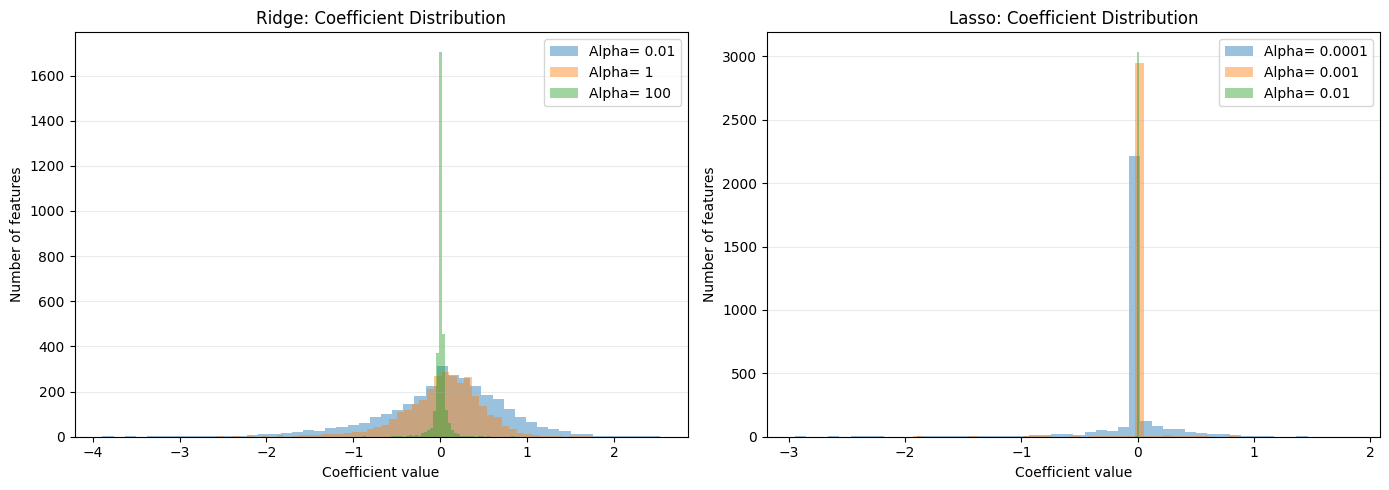

In [32]:
# Select the models trained with all 3,045 features
selected_alphas = {
    "Ridge": [0.01, 1, 100],
    "Lasso": [0.0001, 0.001, 0.01]
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, alphas) in zip(axes, selected_alphas.items()):
    for alpha in alphas:
        model = trained_models[(model_name, alpha)]
        coefficients = np.asarray(model.coef_).ravel()

        ax.hist(
            coefficients,
            bins=50,
            alpha=0.45,
            label=f"Alpha= {alpha}"
        )
    ax.set_title(f"{model_name}: Coefficient Distribution")
    ax.set_xlabel("Coefficient value")
    ax.set_ylabel("Number of features")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import GridSearchCV

ridge_search = GridSearchCV(
    Ridge(solver="lsqr"),
    {"alpha": [0.001, 0.01, 0.1, 1, 10, 100]},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

ridge_search.fit(x_trained_processed, y_train)

best_ridge = ridge_search.best_estimator_
y_pred = best_ridge.predict(x_test_processed)

print("Best Alpha:", ridge_search.best_params_["alpha"])
print("Best CV RMSE:", round(-ridge_search.best_score_, 4))
print("Test MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("Test R2:", round(r2_score(y_test, y_pred), 4))
print(best_ridge)

Best Alpha: 1
Best CV RMSE: 0.7374
Test MAE: 0.5643
Test RMSE: 0.7472
Test R2: 0.542
Ridge(alpha=1, solver='lsqr')


Conclusion – Task 28: Lasso and Ridge Regression


Lasso and Ridge Regression were implemented and compared using different regularization strengths (alpha values). The models were evaluated using MAE, RMSE, and R², and their coefficient distributions were visualized to understand regularization and feature shrinkage.

Ridge Regression with alpha = 1.0 achieved the best reported performance, with a test MAE of 0.5643, RMSE of 0.7472, and R² of 0.5420. Five-fold cross-validation produced an RMSE of 0.7374. Lasso Regression demonstrated feature selection by reducing some coefficients to exactly zero, but stronger regularization reduced predictive performance.

Overall, Ridge Regression was the preferred model for this experiment because it achieved better predictive performance while retaining all 3,045 features.